# Outpatient treatment data preparation

Candidate treatment: intensive (`SERVICES=6`) versus non-intensive (`SERVICES=7`) outpatient placement at admission or transfer, 2022–2023. The primary 14-state set comes from the previously checked 16-state support set, excluding Indiana and Texas because their state source files do not collect one adjustment field each. The earlier 16-state run remains a sensitivity. This is a separate candidate from the frozen residential S1_01/S1_02 analysis.

The two outcome populations use the approved S1 completion and same-substance frequency rules. Missing adjustment fields are retained. Initial overlap diagnostics treat missing as a category; chained categorical imputation then produces two validation draws per outcome and refits propensity scores. These draws do not establish imputation convergence, inferential uncertainty, or causal identification. The timestamped manifest records membership and diagnostics. Run with `helper/run_notebook.py` to save the executed notebook and full HTML review.

In [1]:
import matplotlib
matplotlib.use('Agg')
from pathlib import Path
from datetime import datetime
import sys,json,hashlib,time,warnings
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.exceptions import ConvergenceWarning
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/stage1_specifications.json').is_file())
HOME=ROOT/'S1';HELPER=HOME/'helper';sys.path.insert(0,str(HELPER))
from outcomes import derive_audit_fields,derive_frequency_outcomes
from balance import balance_table,weight_summary
from reporting import Review
BASE_SPEC=json.loads((HELPER/'assets/sample_specification.json').read_text())
FIELDS=BASE_SPEC['fields'];YEARS=(2022,2023)
STATES={'AL':1,'AR':5,'CO':8,'CT':9,'GA':13,'HI':15,'IL':17,'MO':29,'NJ':34,'OH':39,'PA':42,'SD':46,'UT':49,'WY':56}
assert len(STATES)==14 and len(set(STATES.values()))==14 and {18,48}.isdisjoint(STATES.values())
RUN_NAME='S1_03_outpatient_data_preparation'
OUT=HOME/'outputs'/f'{RUN_NAME}_{datetime.now().astimezone():%Y%m%d_%H%M%S_%f}'
OUT.mkdir(parents=True)
review=Review(HOME/'reports',RUN_NAME)
print('Output directory:',OUT)


Output directory: /Users/researcher/code_projects/Causal Discovery /code/project_code/notebooks/code_0927/S1/outputs/S1_03_outpatient_data_preparation_20260926_180001_385313


In [2]:
source_fields=list(dict.fromkeys([f for f in FIELDS if f!='additional_substances_total']+['SERVICES','REASON','SUB2','SUB3','METHUSE','DETCRIM']+[f'{v}{k}_D' for k in (1,2,3) for v in ('SUB','FREQ')]))
pieces=[];source_hashes={};raw_counts=[]
for year in YEARS:
    path=ROOT/f'data/interim/csv/tedsd_puf_{year}.csv'
    with path.open('rb') as stream:digest=hashlib.file_digest(stream,'sha256').hexdigest()
    assert digest==BASE_SPEC['raw_sha256'][str(path.relative_to(ROOT))],f'Raw source changed: {path}'
    source_hashes[str(path.relative_to(ROOT))]=digest
    header=pd.read_csv(path,nrows=0).columns
    columns=['SEX' if c=='GENDER' and 'GENDER' not in header else c for c in source_fields]
    offset=0;retained=0
    for raw in pd.read_csv(path,usecols=columns,chunksize=100000):
        size=len(raw);d=raw.rename(columns={'SEX':'GENDER'}).copy()
        d=d.loc[d.SERVICES.isin([6,7])&d.STFIPS.isin(STATES.values())].copy()
        if len(d):
            d['episode_source_id']=[f'{year}:{offset+int(i)-int(raw.index[0])+1}' for i in d.index]
            d=d.replace(-9,pd.NA)
            for c in d.columns.drop('episode_source_id'):d[c]=d[c].astype('Int64')
            extra=d[['SUB2','SUB3']]
            d['additional_substances_total']=extra.gt(1).fillna(False).sum(axis=1).astype('Int64').mask(extra.isna().any(axis=1))
            d.loc[d.EMPLOY.notna()&d.EMPLOY.ne(4),'DETNLF']=0
            d['treatment']=d.SERVICES.map({6:1,7:0}).astype('Int64')
            pieces.append(d);retained+=len(d)
        offset+=size
    raw_counts.append({'year':year,'public_discharge_rows':offset,'selected_outpatient_episodes':retained})
data=pd.concat(pieces,ignore_index=True).set_index('episode_source_id')
assert data.index.is_unique and len(data)==386282
audit=derive_audit_fields(data);data[audit.columns]=audit
assert int(data.treatment.eq(0).sum())==255239 and int(data.treatment.eq(1).sum())==131043
display(pd.DataFrame(raw_counts))
# The agreed state rule must hold in each year before outcome selection.
counts=data.groupby(['STFIPS','DISYR','treatment']).size().unstack(fill_value=0).reindex(columns=[0,1],fill_value=0)
share=counts[1]/counts.sum(axis=1)
assert len(counts)==28 and counts.min().min()>=1000 and share.between(.2,.8).all()
match_count=sum(data.SUB1.eq(data[f'SUB{k}_D']).fillna(False).astype(int) for k in (1,2,3))
y_frequency=pd.Series(pd.NA,index=data.index,dtype='Int64')
frequency_change=pd.Series(pd.NA,index=data.index,dtype='Int64')
unique=data.loc[match_count.eq(1)]
frequency_derived=derive_frequency_outcomes(unique)
y_frequency.loc[unique.index]=frequency_derived.same_substance_frequency_reduction
frequency_change.loc[unique.index]=frequency_derived.same_substance_frequency_change
samples={};flows=[];availability=[];sensitivity_rows=[]
for outcome in ('completion','frequency'):
    if outcome=='completion':
        target=data.REASON.isin(range(1,8));observed=target;y=data.REASON.eq(1).astype('Int64')
    else:
        target=data.REASON.isin([1,2,3,4,5,7])&data.FREQ1.isin([2,3])
        observed=target&y_frequency.notna();y=y_frequency
    z=data.loc[observed].copy();z['outcome']=y.loc[z.index].astype('Int64')
    if outcome=='frequency':z['frequency_change_3level']=frequency_change.loc[z.index].astype('Int64')
    z['complete_case']=z[FIELDS].notna().all(axis=1).astype(int)
    sensitivity_rows.extend([
        {'outcome':outcome,'definition':'primary_eligible','n':len(z)},
        {'outcome':outcome,'definition':'known_non_none_primary_substance','n':int(z.known_non_none_primary_substance.sum())},
        {'outcome':outcome,'definition':'partial_additional_substance_information','n':int(z.additional_substance_partial_information.sum())},
        {'outcome':outcome,'definition':'METHUSE_observed','n':int(z.METHUSE.notna().sum())},
        {'outcome':outcome,'definition':'DETCRIM_observed_when_PSOURCE_7','n':int((z.PSOURCE.eq(7)&z.DETCRIM.notna()).sum())},
    ])
    if outcome=='completion':sensitivity_rows.append({'outcome':outcome,'definition':'REASON_1_vs_2_3','n':int(z.completion_reason_1_vs_2_3.notna().sum())})
    else:
        for level,label in [(1,'improved'),(0,'unchanged'),(-1,'worsened')]:sensitivity_rows.append({'outcome':outcome,'definition':f'frequency_change_{label}','n':int(z.frequency_change_3level.eq(level).sum())})
    assert z.outcome.notna().all() and z.treatment.notna().all()
    if outcome=='completion':assert len(z)==386282
    else:assert len(z)==152566
    membership_hash=hashlib.sha256(('\n'.join(sorted(z.index))+'\n').encode()).hexdigest()
    z.to_csv(OUT/f'{outcome}_final_eligible.csv.gz',index_label='episode_source_id',compression={'method':'gzip','mtime':0})
    reread=pd.read_csv(OUT/f'{outcome}_final_eligible.csv.gz',usecols=['episode_source_id','treatment','outcome'])
    assert reread.episode_source_id.tolist()==z.index.tolist() and reread.outcome.notna().all()
    samples[outcome]=z
    flows.append({'outcome':outcome,'n':len(z),'comparison_n':int(z.treatment.eq(0).sum()),'intensive_n':int(z.treatment.eq(1).sum()),'complete_case_n':int(z.complete_case.sum()),'membership_sha256':membership_hash})
    for arm in (0,1):
        a=data.treatment.eq(arm)
        availability.append({'outcome':outcome,'arm':arm,'target_n':int((a&target).sum()),'observed_n':int((a&observed).sum())})
flow=pd.DataFrame(flows);availability=pd.DataFrame(availability);sensitivity_audit=pd.DataFrame(sensitivity_rows)
sensitivity_audit.to_csv(OUT/'sample_sensitivity_audit.csv',index=False)
display(flow);display(availability);display(sensitivity_audit)
manifest={'status':'candidate_membership_verified_pending_imputation','treatment':'SERVICES=6 intensive versus SERVICES=7 non-intensive outpatient','years':list(YEARS),'states':STATES,'analysis_role':'primary_14_state','excluded_states':{'IN':18,'TX':48},'selection_reason':'State source files do not collect PRIMINC in IN or PSYPROB in TX; the 16-state run is retained as sensitivity','source_hashes':source_hashes,'raw_counts':raw_counts,'initial_state_year_minimum_arm_n':int(counts.min().min()),'initial_state_year_prevalence_range':[float(share.min()),float(share.max())],'samples':flow.to_dict('records'),'outcome_availability':availability.to_dict('records'),'audit_artifacts':{'sample_sensitivity_audit.csv':hashlib.sha256((OUT/'sample_sensitivity_audit.csv').read_bytes()).hexdigest()},'diagnostic_specification':'Primary membership unchanged; five-fold cross-fitted categorical logistic C=1 with joint state-year interactions; overlap weights; missing category before imputation'}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')


,year,public_discharge_rows,selected_outpatient_episodes
0,2022,1394138,203532
1,2023,1474025,182750


,outcome,n,comparison_n,intensive_n,complete_case_n,membership_sha256
0,completion,386282,255239,131043,244730,de0dfe5d0581975710dc6993a8d70b4b0da94fc02f52b9...
1,frequency,152566,100684,51882,87246,e3bb7a35e1584181fdde641946a063a7abd4f6c1b0a1d8...


,outcome,arm,target_n,observed_n
0,completion,0,255239,255239
1,completion,1,131043,131043
2,frequency,0,138407,100684
3,frequency,1,81994,51882


,outcome,definition,n
0,completion,primary_eligible,386282
1,completion,known_non_none_primary_substance,376798
2,completion,partial_additional_substance_information,59174
3,completion,METHUSE_observed,319922
4,completion,DETCRIM_observed_when_PSOURCE_7,107262
5,completion,REASON_1_vs_2_3,292542
6,frequency,primary_eligible,152566
7,frequency,known_non_none_primary_substance,152566
8,frequency,partial_additional_substance_information,31579
9,frequency,METHUSE_observed,140965


In [3]:
from sklearn.model_selection import StratifiedKFold
def fit_propensity(x,t,fold):
    design=x.astype(str).copy();cell=design.STFIPS+'|'+design.DISYR;design['state_year']=cell
    for col in x:
        if col not in ('STFIPS','DISYR'):design['state_year_by_'+col]=cell+'|'+design[col]
    e=np.full(len(x),np.nan);audits=[]
    for k in range(5):
        train=fold!=k;test=fold==k
        assert set(t[train])==set(t[test])=={0,1}
        model=make_pipeline(OneHotEncoder(handle_unknown='ignore'),LogisticRegression(C=1,solver='lbfgs',max_iter=10000,tol=1e-6))
        with warnings.catch_warnings():
            warnings.simplefilter('error',ConvergenceWarning)
            model.fit(design.loc[train],t[train])
        e[test]=model.predict_proba(design.loc[test])[:,1]
        audits.append({'fold':k,'iterations':int(model[-1].n_iter_[0])})
    assert np.isfinite(e).all() and ((e>0)&(e<1)).all()
    return e,audits
summaries=[];years=[];locals_=[];folds={}
for outcome,z in samples.items():
    print('Checking outpatient overlap:',outcome,len(z),flush=True)
    x=z[FIELDS];t=z.treatment.to_numpy(int);fold=np.full(len(z),-1)
    for k,(_,idx) in enumerate(StratifiedKFold(5,shuffle=True,random_state=720).split(x,t)):fold[idx]=k
    folds[outcome]=fold
    e,audits=fit_propensity(x,t,fold);w=np.where(t==1,1-e,e)
    enc=pd.get_dummies(x.astype(str),dtype=float);balance=balance_table(enc,t,w);ess=weight_summary(t,w)
    tail=((e<.05)|(e>.95));assert balance.abs_smd.max()<.1
    summaries.append({'outcome':outcome,'n':len(z),'outside_005_095_percent':float(100*tail.mean()),'max_weighted_smd':float(balance.abs_smd.max()),'comparison_ess':float(ess.iloc[0].effective_sample_size),'intensive_ess':float(ess.iloc[1].effective_sample_size),'fold_iterations':[a['iterations'] for a in audits]})
    for year in YEARS:
        idx=np.flatnonzero(z.DISYR.eq(year).to_numpy());b=balance_table(enc.iloc[idx],t[idx],w[idx]);q=weight_summary(t[idx],w[idx]);v=float(100*tail[idx].mean())
        years.append({'outcome':outcome,'year':year,'n':len(idx),'outside_005_095_percent':v,'max_weighted_smd':float(b.abs_smd.max()),'minimum_arm_ess_share':float(min(q.iloc[0].effective_sample_size/(t[idx]==0).sum(),q.iloc[1].effective_sample_size/(t[idx]==1).sum()))})
        assert b.abs_smd.max()<.1 and years[-1]['minimum_arm_ess_share']>.25
    for (state,year),idx in z.groupby(['STFIPS','DISYR']).indices.items():
        assert set(t[idx])=={0,1}
        b=balance_table(enc.iloc[idx],t[idx],w[idx]);q=weight_summary(t[idx],w[idx]);p=enc.iloc[idx].mean()
        flag=b.variable.map(p).between(.05,.95)&b.difference.abs().gt(.05)&(b.abs_smd.gt(.1)|(b.zero_reference_scale&b.difference.abs().gt(1e-10)))
        row={'outcome':outcome,'state':int(state),'year':int(year),'n':len(idx),'flagged_categories':int(flag.sum()),'minimum_arm_ess':float(q.effective_sample_size.min())};locals_.append(row)
        assert row['flagged_categories']==0 and row['minimum_arm_ess']>=50
    print('Score-tail threshold (<10%) passed:',outcome,all(r['outside_005_095_percent']<10 for r in years if r['outcome']==outcome) and summaries[-1]['outside_005_095_percent']<10)
summary=pd.DataFrame(summaries);year_summary=pd.DataFrame(years);local=pd.DataFrame(locals_)
display(summary);display(year_summary);display(local.groupby('outcome').agg(cells=('n','size'),minimum_arm_ess=('minimum_arm_ess','min'),flagged_cells=('flagged_categories',lambda v:int((v>0).sum()))))
tail_gate_passed=bool(summary.outside_005_095_percent.lt(10).all() and year_summary.outside_005_095_percent.lt(10).all())
manifest['pre_imputation_diagnostics']={'pooled':summary.to_dict('records'),'by_year':year_summary.to_dict('records'),'local':local.to_dict('records'),'score_tail_threshold_percent':10,'score_tail_gate_passed':tail_gate_passed}
manifest['status']='candidate_membership_and_pre_imputation_overlap_verified' if tail_gate_passed else 'candidate_membership_verified_overlap_review_required'
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')


Checking outpatient overlap: completion 386282
Score-tail threshold (<10%) passed: completion True
Checking outpatient overlap: frequency 152566
Score-tail threshold (<10%) passed: frequency False


,outcome,n,outside_005_095_percent,max_weighted_smd,comparison_ess,intensive_ess,fold_iterations
0,completion,386282,9.426792,0.000872,166439.849996,109948.81798,"[1203, 1383, 1238, 1276, 1300]"
1,frequency,152566,10.619666,0.003875,61429.848292,40888.32167,"[963, 973, 1079, 1035, 893]"


,outcome,year,n,outside_005_095_percent,max_weighted_smd,minimum_arm_ess_share
0,completion,2022,203532,9.706090,0.004492,0.640350
1,completion,2023,182750,9.115732,0.003061,0.665842
2,frequency,2022,81029,11.109603,0.007257,0.597165
3,frequency,2023,71537,10.064722,0.004950,0.624931


,cells,minimum_arm_ess,flagged_cells
outcome,,,
completion,28,462.170701,0
frequency,28,245.878228,0


In [4]:
def validate_imputation(chain_sample, OUT, seed):
    from sklearn.model_selection import StratifiedKFold
    chain_fields=[f for f in FIELDS if f not in ['EMPLOY','DETNLF']]+['employment_joint','treatment','outcome']
    base=chain_sample[[f for f in chain_fields if f!='employment_joint']].astype(float)
    base['employment_joint']=(10*chain_sample.EMPLOY).astype(float)
    parent_four=chain_sample.EMPLOY.eq(4).fillna(False)
    base.loc[parent_four,'employment_joint']=(40+chain_sample.loc[parent_four,'DETNLF']).astype(float)
    base=base[chain_fields]
    slots=chain_sample[['SUB2','SUB3']]
    lower=slots.gt(1).fillna(False).sum(axis=1).to_numpy();upper=lower+slots.isna().sum(axis=1).to_numpy()
    def feasible(field,classes,rows):
        vals=np.asarray(classes);result=np.ones((len(rows),len(vals)),dtype=bool)
        if field=='additional_substances_total':result=(vals[None,:]>=lower[rows,None])&(vals[None,:]<=upper[rows,None])
        if field=='employment_joint':
            parent=chain_sample.EMPLOY.to_numpy(dtype=float,na_value=np.nan)[rows]
            detail=chain_sample.DETNLF.to_numpy(dtype=float,na_value=np.nan)[rows]
            result&=np.isnan(parent[:,None])|(vals[None,:]//10==parent[:,None])
            known=np.isfinite(detail)&(detail>0)
            result[known]&=vals[None,:]==(40+detail[known,None])
            result[np.isfinite(detail)&(detail==0)]&=vals[None,:]<40
        return result
    # Separate stochastic chains on fixed outpatient membership; not inferential MI.
    rng=np.random.default_rng(seed);targets=base.columns[base.isna().any()].tolist();chain_rows=[];chain_balance=[];chain_traces=[];chain_local=[]
    fold=np.full(len(base),-1)
    for k,(_,idx) in enumerate(StratifiedKFold(5,shuffle=True,random_state=720).split(base,base.treatment)):fold[idx]=k
    for chain in range(2):
        print('Full-population chain',chain+1,'of 2',flush=True)
        start=time.perf_counter();z=base.copy()
        for field in targets:
            classes,counts=np.unique(base[field].dropna(),return_counts=True);rows=np.flatnonzero(base[field].isna())
            prob=feasible(field,classes,rows)*counts[None,:]
            assert (prob.sum(axis=1)>0).all(),field
            prob=prob/prob.sum(axis=1)[:,None]
            z.loc[base[field].isna(),field]=[rng.choice(classes,p=r) for r in prob]
        for iteration in range(10):
            print('Chain',chain+1,'iteration',iteration+1,'of 10',flush=True)
            for field in targets:
                observed=base[field].notna();rows=np.flatnonzero(~observed)
                x=z.drop(columns=field).astype(str);x['state_year']=x.STFIPS+'|'+x.DISYR;x['treatment_outcome']=x.treatment+'|'+x.outcome
                classes=np.sort(base.loc[observed,field].unique())
                if len(classes)==1:prob=np.ones((len(rows),1))
                else:
                    model=make_pipeline(OneHotEncoder(handle_unknown='ignore'),LogisticRegression(C=1,max_iter=2000))
                    w=rng.exponential(size=observed.sum());w/=w.mean()
                    with warnings.catch_warnings():
                        warnings.simplefilter('error',ConvergenceWarning)
                        model.fit(x.loc[observed],base.loc[observed,field].astype(int),logisticregression__sample_weight=w)
                    classes=model[-1].classes_;prob=model.predict_proba(x.loc[~observed])
                prob*=feasible(field,classes,rows);assert (prob.sum(axis=1)>0).all(),field
                prob/=prob.sum(axis=1)[:,None]
                z.loc[~observed,field]=[rng.choice(classes,p=r) for r in prob]
            for field in targets:
                missing_mask=base[field].isna()
                for category,share in z.loc[missing_mask,field].value_counts(normalize=True).items():
                    chain_traces.append(dict(chain=chain+1,iteration=iteration+1,field=field,category=category,share=share))
            assert not z.isna().any().any()
            for field in base:
                obs=base[field].notna();assert np.array_equal(z.loc[obs,field],base.loc[obs,field])
            assert z.employment_joint.isin([10,20,30,41,42,43,44,45]).all()
            assert z.additional_substances_total.between(lower,upper).all()
        complete=z.copy();complete['EMPLOY']=complete.employment_joint//10
        complete['DETNLF']=np.where(complete.EMPLOY.eq(4),complete.employment_joint%10,0)
        for field in ['EMPLOY','DETNLF']:
            obs=chain_sample[field].notna();assert np.array_equal(complete.loc[obs,field],chain_sample.loc[obs,field].astype(float))
        e,_=fit_propensity(complete[FIELDS],complete.treatment.to_numpy(int),fold)
        w=np.where(complete.treatment.eq(1),1-e,e)
        b=balance_table(pd.get_dummies(complete[FIELDS].astype(str),dtype=float),complete.treatment,w)
        b['chain']=chain+1;chain_balance.append(b)
        for (state,year),g in complete.groupby(['STFIPS','DISYR']):
            positions=complete.index.get_indexer(g.index);local_w=w[positions]
            lx=pd.get_dummies(g[FIELDS].astype(str),dtype=float)
            lb=balance_table(lx,g.treatment,local_w)
            prevalence=lx.mean().reindex(lb.variable).to_numpy()
            flag=(prevalence>=.05)&(prevalence<=.95)&lb.difference.abs().gt(.05)&(lb.abs_smd.gt(.1)|(lb.zero_reference_scale&lb.difference.ne(0)))
            support=weight_summary(g.treatment,local_w)
            chain_local.append(dict(chain=chain+1,state=state,year=year,n=len(g),flagged_categories=int(flag.sum()),minimum_arm_ess=support.effective_sample_size.min()))
        ess=weight_summary(complete.treatment,w)
        chain_rows.append(dict(chain=chain+1,n=len(complete),iterations=10,max_abs_smd=b.abs_smd.max(),outside_005_095_percent=100*((e<.05)|(e>.95)).mean(),nonintensive_ess=ess.loc[ess.treatment.eq(0),'effective_sample_size'].iloc[0],intensive_ess=ess.loc[ess.treatment.eq(1),'effective_sample_size'].iloc[0],seconds=time.perf_counter()-start))
        complete['propensity']=e;complete['overlap_weight']=w
        complete.to_csv(OUT/f'engineering_imputation_chain_{chain+1}.csv.gz',index_label='episode_source_id',compression={'method':'gzip','mtime':0})
    chain_summary=pd.DataFrame(chain_rows)
    display(chain_summary);review.table('Full-population chained-imputation validation',chain_summary)
    review.note('All observed values and both structural constraints were checked in the eligible episodes. Two ten-iteration chains assess implementation and balance; uncertainty calibration and chain stability require separate review.')
    traces=pd.DataFrame(chain_traces)
    local_checks=pd.DataFrame(chain_local)
    display(local_checks);review.table('Full-population local support and balance',local_checks)
    # Compare categorical shares using common columns, including categories absent in a draw.
    wide=traces.pivot_table(index=['chain','iteration'],columns=['field','category'],values='share',fill_value=0)
    changes=[]
    for chain in [1,2]:
        block=wide.loc[chain];last=block.loc[6:10]
        changes.append(dict(chain=chain,max_category_share_change_2_to_10=(block.loc[10]-block.loc[2]).abs().max(),max_category_share_range_last5=(last.max()-last.min()).max()))
    stability=pd.DataFrame(changes)
    display(stability);review.table('Categorical trace stability',stability)
    review.note('Local ESS and balance refer to the full eligible observed-outcome population. Category-share traces describe ten iterations; convergence and inferential validity remain separate checks.')
    review.mark('Run constrained chained-imputation validation')
    return dict(base=base, targets=targets, fold=fold, wide=wide, traces=traces)


In [5]:
imputation_runs={'completion':[722],'frequency':[720]}
draws=[]
for outcome,seeds in imputation_runs.items():
    for seed in seeds:
        folder=OUT/f'{outcome}_imputation_seed{seed}';folder.mkdir()
        result=validate_imputation(samples[outcome],folder,seed)
        for chain in (1,2):
            path=folder/f'engineering_imputation_chain_{chain}.csv.gz'
            draw=pd.read_csv(path,usecols=['episode_source_id','treatment','outcome','propensity','overlap_weight']).set_index('episode_source_id')
            assert draw.index.equals(samples[outcome].index)
            np.testing.assert_array_equal(draw.treatment.to_numpy(int),samples[outcome].treatment.to_numpy(int))
            np.testing.assert_array_equal(draw.outcome.to_numpy(int),samples[outcome].outcome.to_numpy(int))
            np.testing.assert_allclose(draw.overlap_weight,np.where(draw.treatment.eq(1),1-draw.propensity,draw.propensity),rtol=0,atol=1e-10)
            draws.append({'outcome':outcome,'seed':seed,'chain':chain,'file':str(path.relative_to(OUT)),'n':len(draw),'sha256':hashlib.sha256(path.read_bytes()).hexdigest()})
manifest['imputation']={'runs':imputation_runs,'chains_per_seed':2,'iterations_per_chain':10,'draws':draws,'role':'validation draws; inferential MI count and convergence remain pending'}
manifest['status']='candidate_membership_and_four_imputation_draws_verified' if tail_gate_passed else 'candidate_membership_and_four_imputation_draws_verified_overlap_review_required'
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
print('Validated outpatient sample and draw folder:',OUT)


Full-population chain 1 of 2
Chain 1 iteration 1 of 10
Chain 1 iteration 2 of 10
Chain 1 iteration 3 of 10
Chain 1 iteration 4 of 10
Chain 1 iteration 5 of 10
Chain 1 iteration 6 of 10
Chain 1 iteration 7 of 10
Chain 1 iteration 8 of 10
Chain 1 iteration 9 of 10
Chain 1 iteration 10 of 10
Full-population chain 2 of 2
Chain 2 iteration 1 of 10
Chain 2 iteration 2 of 10
Chain 2 iteration 3 of 10
Chain 2 iteration 4 of 10
Chain 2 iteration 5 of 10
Chain 2 iteration 6 of 10
Chain 2 iteration 7 of 10
Chain 2 iteration 8 of 10
Chain 2 iteration 9 of 10
Chain 2 iteration 10 of 10
Full-population chain 1 of 2
Chain 1 iteration 1 of 10
Chain 1 iteration 2 of 10
Chain 1 iteration 3 of 10
Chain 1 iteration 4 of 10
Chain 1 iteration 5 of 10
Chain 1 iteration 6 of 10
Chain 1 iteration 7 of 10
Chain 1 iteration 8 of 10
Chain 1 iteration 9 of 10
Chain 1 iteration 10 of 10
Full-population chain 2 of 2
Chain 2 iteration 1 of 10
Chain 2 iteration 2 of 10
Chain 2 iteration 3 of 10
Chain 2 iteration 4 of 

,chain,n,iterations,max_abs_smd,outside_005_095_percent,nonintensive_ess,intensive_ess,seconds
0,1,386282,10,0.000987,7.583579,171511.404186,111254.066044,2096.562741
1,2,386282,10,0.000851,7.558727,171483.154449,111285.519900,2091.497519


,chain,state,year,n,flagged_categories,minimum_arm_ess
0,1,1.0,2022.0,6685,0,1682.260602
1,1,1.0,2023.0,7605,0,1872.781307
2,1,5.0,2022.0,4285,0,624.546824
3,1,5.0,2023.0,4616,0,480.287297
4,1,8.0,2022.0,23986,0,4377.639143
5,1,8.0,2023.0,6060,0,1247.920073
6,1,9.0,2022.0,25642,0,5045.933747
7,1,9.0,2023.0,24081,0,5131.023800
8,1,13.0,2022.0,22861,0,4223.515593
9,1,13.0,2023.0,21822,0,4157.831740


,chain,max_category_share_change_2_to_10,max_category_share_range_last5
0,1,0.01992,0.083665
1,2,0.02427,0.035857


,chain,n,iterations,max_abs_smd,outside_005_095_percent,nonintensive_ess,intensive_ess,seconds
0,1,152566,10,0.003357,8.241679,63987.986372,41766.137280,659.848169
1,2,152566,10,0.003761,8.311813,63866.308313,41724.133699,664.905073


,chain,state,year,n,flagged_categories,minimum_arm_ess
0,1,1.0,2022.0,2718,0,716.924231
1,1,1.0,2023.0,3060,0,839.613564
2,1,5.0,2022.0,2794,0,460.745504
3,1,5.0,2023.0,3081,0,347.631142
4,1,8.0,2022.0,12917,0,2621.538989
5,1,8.0,2023.0,3009,0,629.155979
6,1,9.0,2022.0,12300,0,2752.806473
7,1,9.0,2023.0,11932,0,2948.232099
8,1,13.0,2022.0,12954,0,3221.979270
9,1,13.0,2023.0,12752,0,3380.672336


,chain,max_category_share_change_2_to_10,max_category_share_range_last5
0,1,0.060606,0.131313
1,2,0.046429,0.090909


## Propensity figures for the fixed eligible samples

Each outcome uses the first saved imputation validation draw, with the exact frozen episode membership. The left panel shows the score distribution within each treatment arm before weighting; the right panel shows the same episodes after overlap weighting. Each arm is normalized separately, so panel height is a density rather than the number of episodes. Dotted lines mark scores 0.05 and 0.95 as descriptive tail guides. These plots describe measured treatment overlap and the population emphasized by the weights. State–year balance and imputation diagnostics are assessed separately.

HTML review: /Users/researcher/code_projects/Causal Discovery /code/project_code/notebooks/code_0927/S1/reports/S1_03_outpatient_data_preparation_20260926_193519_556994.html
Propensity figures: ['completion_propensity_eligible_draw1.png', 'frequency_propensity_eligible_draw1.png']


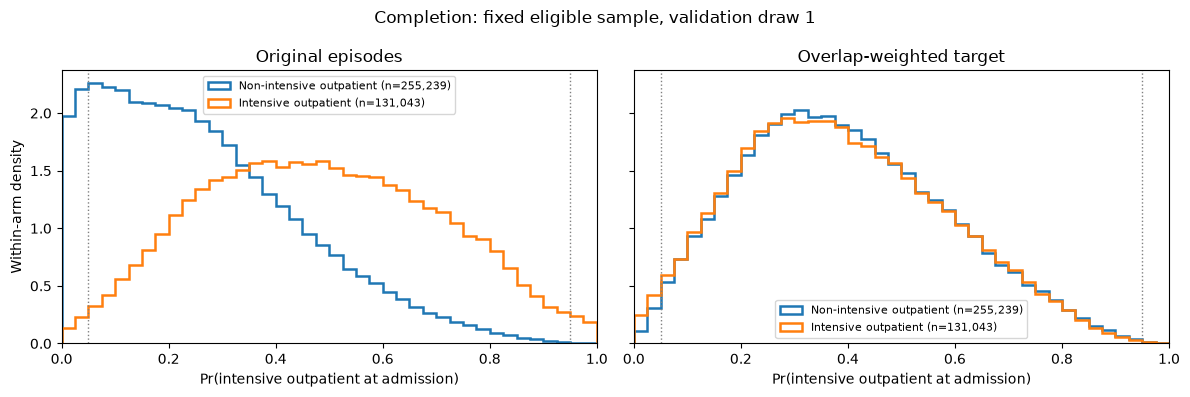

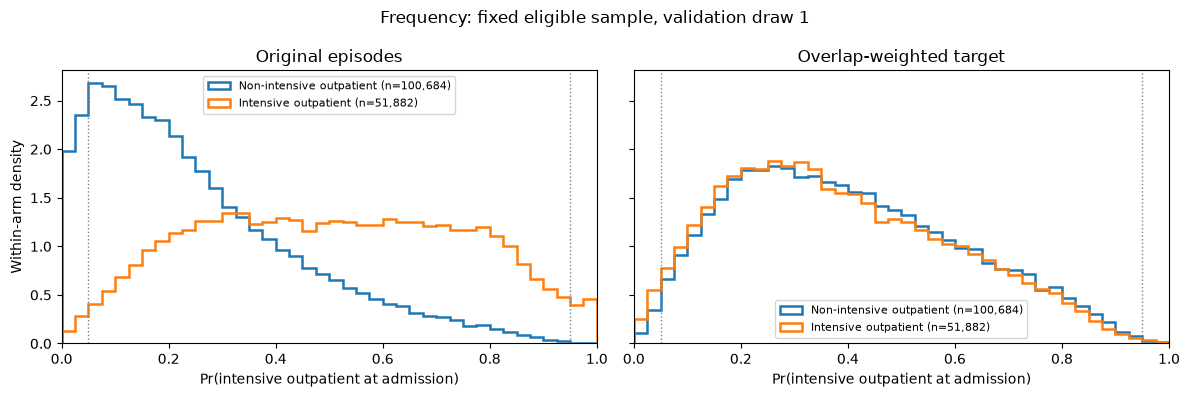

In [6]:
from balance import plot_propensity_distributions
import matplotlib.pyplot as plt
figures=[]
for outcome,seed in (('completion',722),('frequency',720)):
    eligible=pd.read_csv(OUT/f'{outcome}_final_eligible.csv.gz',usecols=['episode_source_id','treatment'])
    source=OUT/f'{outcome}_imputation_seed{seed}/engineering_imputation_chain_1.csv.gz'
    draw=pd.read_csv(source,usecols=['episode_source_id','treatment','propensity','overlap_weight'])
    assert len(draw)==len(eligible) and draw.episode_source_id.equals(eligible.episode_source_id)
    np.testing.assert_array_equal(draw.treatment.to_numpy(),eligible.treatment.to_numpy())
    np.testing.assert_allclose(draw.overlap_weight,np.where(draw.treatment.eq(1),1-draw.propensity,draw.propensity),rtol=0,atol=1e-10)
    fig=plot_propensity_distributions(draw.propensity,draw.treatment,draw.overlap_weight,
        labels=('Non-intensive outpatient','Intensive outpatient'),title=f'{outcome.title()}: fixed eligible sample, validation draw 1',
        score_label='Pr(intensive outpatient at admission)')
    image_path=OUT/f'{outcome}_propensity_eligible_draw1.png'
    fig.savefig(image_path,dpi=160)
    display(fig);plt.close(fig)
    review.figure(f'{outcome} eligible-sample propensity distributions',image_path)
    figures.append({'outcome':outcome,'file':image_path.name,'source_draw':str(source.relative_to(OUT)),
                    'n':len(draw),'sha256':hashlib.sha256(image_path.read_bytes()).hexdigest()})
manifest['propensity_figures']=figures
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
review.mark('Verify fixed eligible membership and export propensity figures')
report_path=review.export();print('HTML review:',report_path)
print('Propensity figures:',[item['file'] for item in figures])